In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

In [ ]:
# API_KEY="1sssss44ssss25c3695sssss1971ssss6b6cf19d3asssss170sssss4830sssss9"
CITY = "Pune"
url = "https://api.openweathermap.org/data/2.5/forecast"
resp = requests.get(url, params={"q": CITY, "appid": API_KEY, "units": "metric"})
data = resp.json()

In [40]:
# Extract relevant attributes
rows = []
for item in data["list"]:
    rows.append({"datetime": item["dt_txt"],
                "temp": item["main"]["temp"],
                "humidity": item["main"]["humidity"],
                "wind_speed": item["wind"]["speed"],
                "rain": item.get("rain", {}).get("3h", 0)
            })
    
df = pd.DataFrame(rows)
print(df.head())

              datetime   temp  humidity  wind_speed  rain
0  2026-11-02 12:00:00  24.13        63        0.58  0.00
1  2026-11-02 15:00:00  23.64        67        0.35  0.16
2  2026-11-02 18:00:00  22.61        75        1.02  0.64
3  2026-11-02 21:00:00  21.37        83        0.82  0.70
4  2026-11-03 00:00:00  20.98        83        0.39  0.00


In [32]:
# Cleaning 
df["datetime"]=pd.to_datetime(df["datetime"])
df=df.drop_duplicates().fillna(0)
df=df.set_index("datetime")


In [34]:
df.head(2)

,temp,humidity,wind_speed,rain
datetime,,,,
2026-11-02 12:00:00,24.13,63,0.58,0.00
2026-11-02 15:00:00,23.64,67,0.35,0.16


In [39]:
# Modeling / statistics
print("Average temp:", df["temp"].mean())
print("Max temp:", df["temp"].max(), " Min temp:", df["temp"].min())
daily = df.resample("D").agg({"temp": "mean", "humidity": "mean","wind_speed": "mean", "rain": "sum"})
print(daily)

Average temp: 26.082500000000003
Max temp: 31.29  Min temp: 20.98
                temp  humidity  wind_speed  rain
datetime                                        
2026-11-02  22.93750    72.000     0.69250   1.5
2026-11-03  26.00625    62.375     1.58875   0.0
2026-11-04  26.59125    58.375     1.96000   0.1
2026-11-05  26.48375    53.875     2.07375   0.0
2026-11-06  26.71875    44.000     2.11250   0.0
2026-11-07  26.28750    35.000     2.98500   0.0


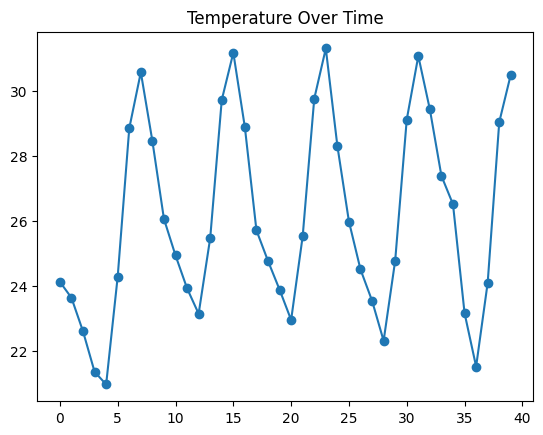

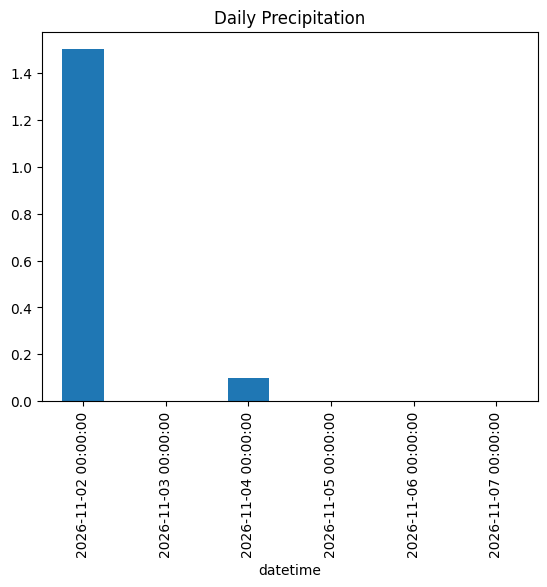

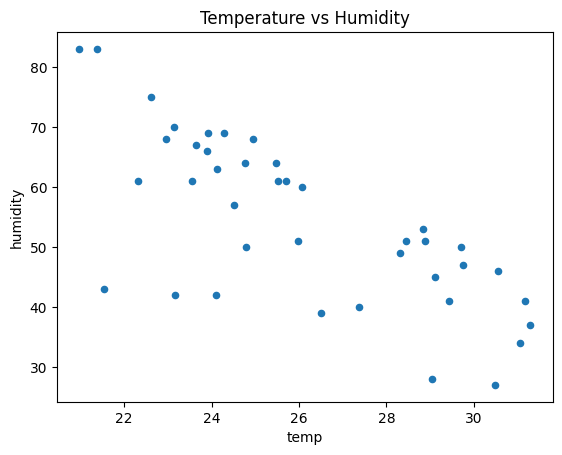

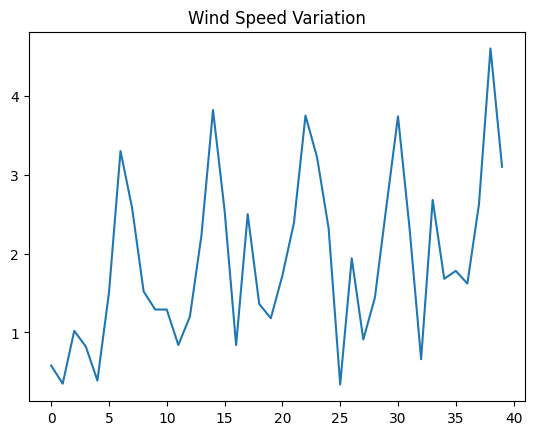

In [41]:
# Visualization
df["temp"].plot(title="Temperature Over Time", marker="o"); plt.show()
daily["rain"].plot(kind="bar", title="Daily Precipitation"); plt.show()
df.plot.scatter(x="temp", y="humidity", title="Temperature vs Humidity");
plt.show()
df["wind_speed"].plot(title="Wind Speed Variation"); plt.show() 

In [ ]:
# Geographical visualization (multiple cities)
cities = ["Pune", "Mumbai", "Delhi", "Chennai", "Kolkata"]
loc = []
for c in cities:
 r = requests.get("https://api.openweathermap.org/data/2.5/weather",
 params={"q": c, "appid": API_KEY, "units": "metric"}).json()
 loc.append({"city": c, "lat": r["coord"]["lat"], "lon": r["coord"]["lon"],
 "temp": r["main"]["temp"]})
geo = pd.DataFrame(loc)
plt.scatter(geo.lon, geo.lat, c=geo.temp, s=200, cmap="coolwarm")
plt.colorbar(label="Temp (C)")
for i, r in geo.iterrows():
 plt.text(r.lon, r.lat, r.city)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.show()
# Correlation heatmap
sns.heatmap(df.corr(), annot=True, cmap="coolwarm"); plt.show()